In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
import noisereduce as nr
import whisper

from IPython.display import Audio, display

In [2]:
# configure our visualization.

plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.grid"] = True

In [3]:
# creating path for output
os.makedirs("output", exist_ok=True)

In [4]:
audio_path = "10_second_speech_with_noise.wav"

if not os.path.exists(audio_path):
    raise FileNotFoundError(
        f"Audio file not found: {audio_path}"
    )

print("Audio file loaded:", audio_path)

Audio file loaded: 10_second_speech_with_noise.wav


In [5]:
info = sf.info(audio_path)
print(info)

10_second_speech_with_noise.wav
samplerate: 22050 Hz
channels: 1
duration: 10.000 s
format: WAV (Microsoft) [WAV]
subtype: Signed 16 bit PCM [PCM_16]


In [6]:
duration = info.duration
sample_rate = info.samplerate
channels = info.channels
frames = info.frames
subtype = info.subtype
format_name = info.format

print("Audio Information")
print("----------------------")

print("Duration:", round(duration, 2), "seconds")

print("Sampling Rate:", sample_rate, "Hz")

print("Channels:", channels)

print("Total Samples per Channel:", frames)

print("Format:", format_name)

print("Subtype:", subtype)

Audio Information
----------------------
Duration: 10.0 seconds
Sampling Rate: 22050 Hz
Channels: 1
Total Samples per Channel: 220500
Format: WAV
Subtype: PCM_16


In [7]:
# Determine bit depth

def get_bit_depth(subtype):

    bit_depths = {
        "PCM_U8": 8,
        "PCM_16": 16,
        "PCM_24": 24,
        "PCM_32": 32,
        "FLOAT": 32,
        "DOUBLE": 64
    }

    return bit_depths.get(subtype, "Unknown / format-dependent")


bit_depth = get_bit_depth(subtype)

print("Bit Depth:", bit_depth)

Bit Depth: 16


In [8]:
audio_info = pd.DataFrame({
    "Property": [
        "Duration",
        "Sampling Rate",
        "Channels",
        "Total Frames",
        "Bit Depth",
        "Format"
    ],

    "Value": [
        f"{duration:.2f} seconds",
        f"{sample_rate} Hz",
        channels,
        frames,
        bit_depth,
        format_name
    ]
})

display(audio_info)

,Property,Value
0,Duration,10.00 seconds
1,Sampling Rate,22050 Hz
2,Channels,1
3,Total Frames,220500
4,Bit Depth,16
5,Format,WAV


In [9]:
audio,sr = librosa.load(
    audio_path,
    sr= None,
    mono= False
)

print("Sample Rate:", sr)
print("Audio Shape:", audio.shape)

Sample Rate: 22050
Audio Shape: (220500,)


In [10]:
# converting mono audio if multiplie channels are present 

if audio.ndim == 2:
   audio_mono = np.mean(audio, axis=0) 

else:
    audio_mono = audio.copy()

print("Mono Audio Shape:", audio_mono.shape)

Mono Audio Shape: (220500,)


In [11]:
display(
    Audio(
        audio,
        rate=sr
    )
)

display(
    Audio(
        audio_mono,
        rate=sr,
        normalize=True
    )
)

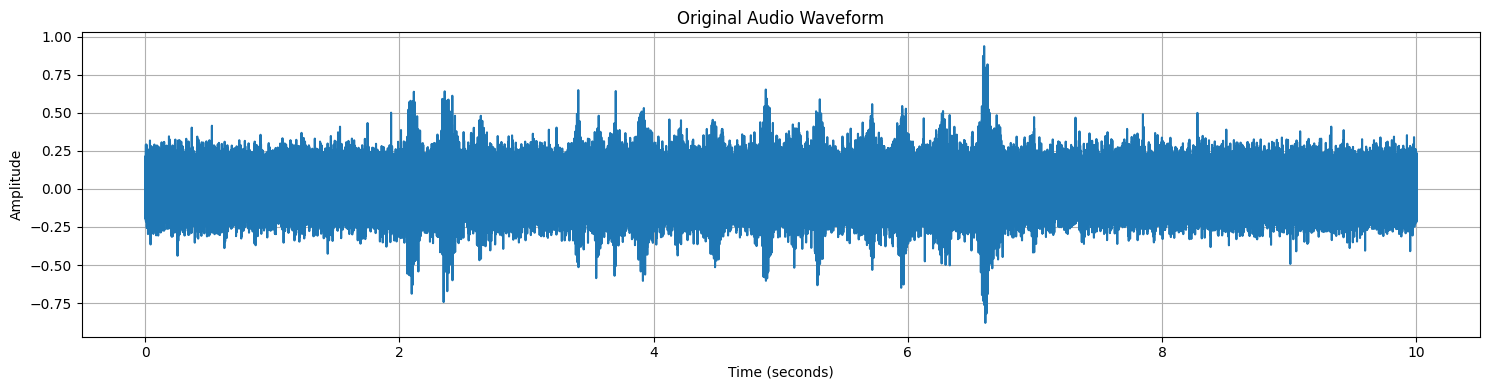

In [12]:
# Waveform Visualization

time = np.arange(len(audio_mono))/sr 

plt.figure(figsize=(15,4))

plt.plot(time,audio_mono)

plt.title("Original Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [13]:
# Spectrogram Visualization

# calculate STFT 

n_fft = 1024
hop_length = 256

stft = librosa.stft(
    audio_mono,
    n_fft=n_fft,
    hop_length=hop_length
)

magnitude = np.abs(stft)

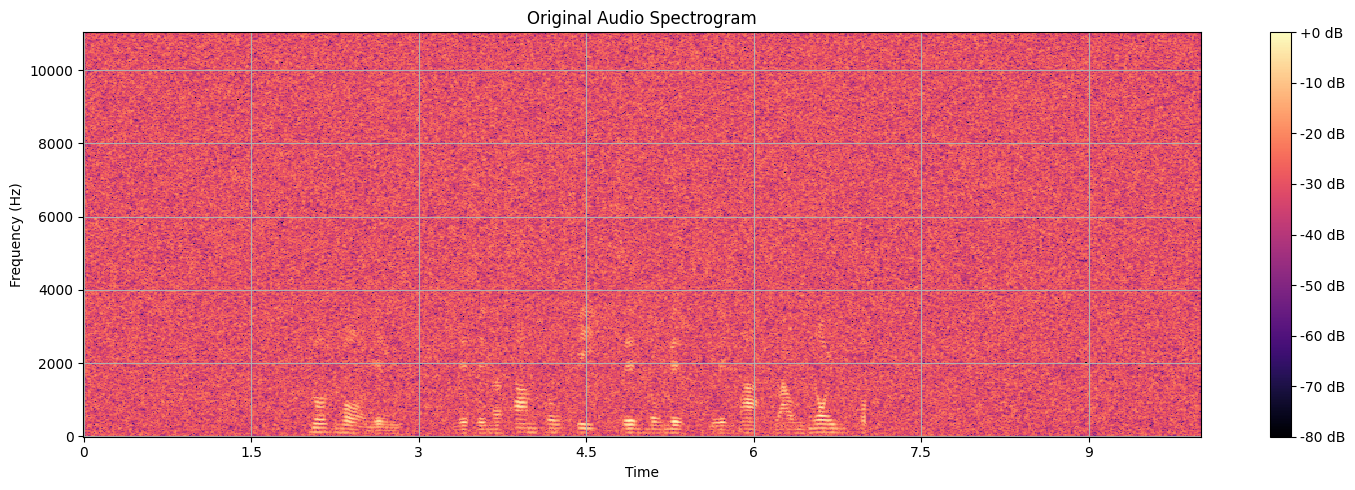

In [14]:
spectrogram_db = librosa.amplitude_to_db(
    magnitude,
    ref=np.max
)

plt.figure(figsize=(15, 5))

librosa.display.specshow(
    spectrogram_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="hz"
)

plt.colorbar(format="%+2.0f dB")

plt.title("Original Audio Spectrogram")
plt.xlabel("Time")
plt.ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

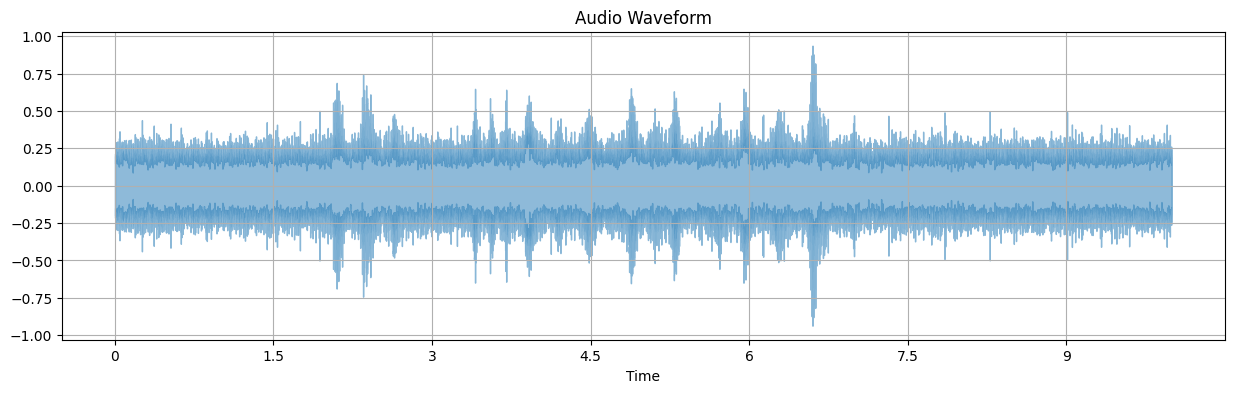

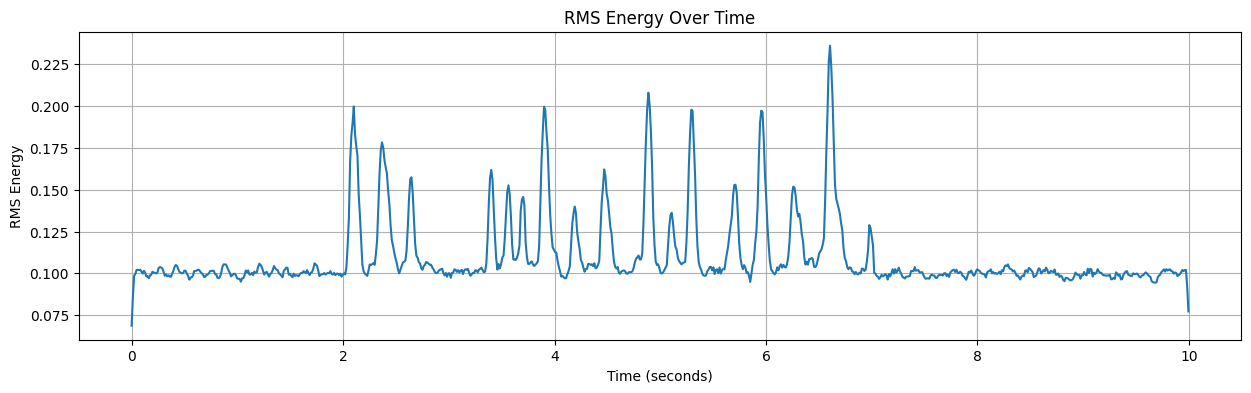

In [15]:
# Noise Analysis

rms = librosa.feature.rms(
    y=audio_mono,
    frame_length=1024,
    hop_length=256
)[0]

plt.figure(figsize=(15, 4))

librosa.display.waveshow(
    audio_mono,
    sr=sr,
    alpha=0.5
)

plt.title("Audio Waveform")
plt.show()

plt.figure(figsize=(15, 4))

times = librosa.frames_to_time(
    np.arange(len(rms)),
    sr=sr,
    hop_length=256
)

plt.plot(times, rms)

plt.title("RMS Energy Over Time")
plt.xlabel("Time (seconds)")
plt.ylabel("RMS Energy")

plt.show()

In [16]:
noise_start = 0.0
noise_end = 2.0

noise_clip = audio_mono[
    int(noise_start * sr):
    int(noise_end * sr)
]

if len(noise_clip) == 0:
    raise ValueError("Noise sample is empty.")

display(Audio(noise_clip, rate=sr))

In [17]:
# Estimate signal and noise levels

def calculate_rms(signal):

    return np.sqrt(
        np.mean(signal ** 2)
    )


noise_rms = calculate_rms(noise_clip)

signal_rms = calculate_rms(audio_mono)

print("Overall Audio RMS:", signal_rms)

print("Noise Sample RMS:", noise_rms)

Overall Audio RMS: 0.11250144
Noise Sample RMS: 0.10039731


In [18]:
epsilon = 1e-10

estimated_snr = 20 * np.log10(
    (signal_rms + epsilon) /
    (noise_rms + epsilon)
)

print("Estimated SNR:", round(estimated_snr, 2), "dB")

Estimated SNR: 0.99 dB


In [19]:
# Noise Reduction

reduced_audio = nr.reduce_noise(
    y=audio_mono,
    sr=sr,
    y_noise=noise_clip,
    stationary=True,
    prop_decrease=0.99
)

display(
    Audio(
        audio_mono,
        rate=sr
    )
)

display(
    Audio(
        reduced_audio,
        rate=sr
    )
)

In [20]:
enhanced_path = "output/enhanced_audio.wav"

sf.write(
    enhanced_path,
    reduced_audio,
    sr
)

print("Saved:", enhanced_path)

Saved: output/enhanced_audio.wav


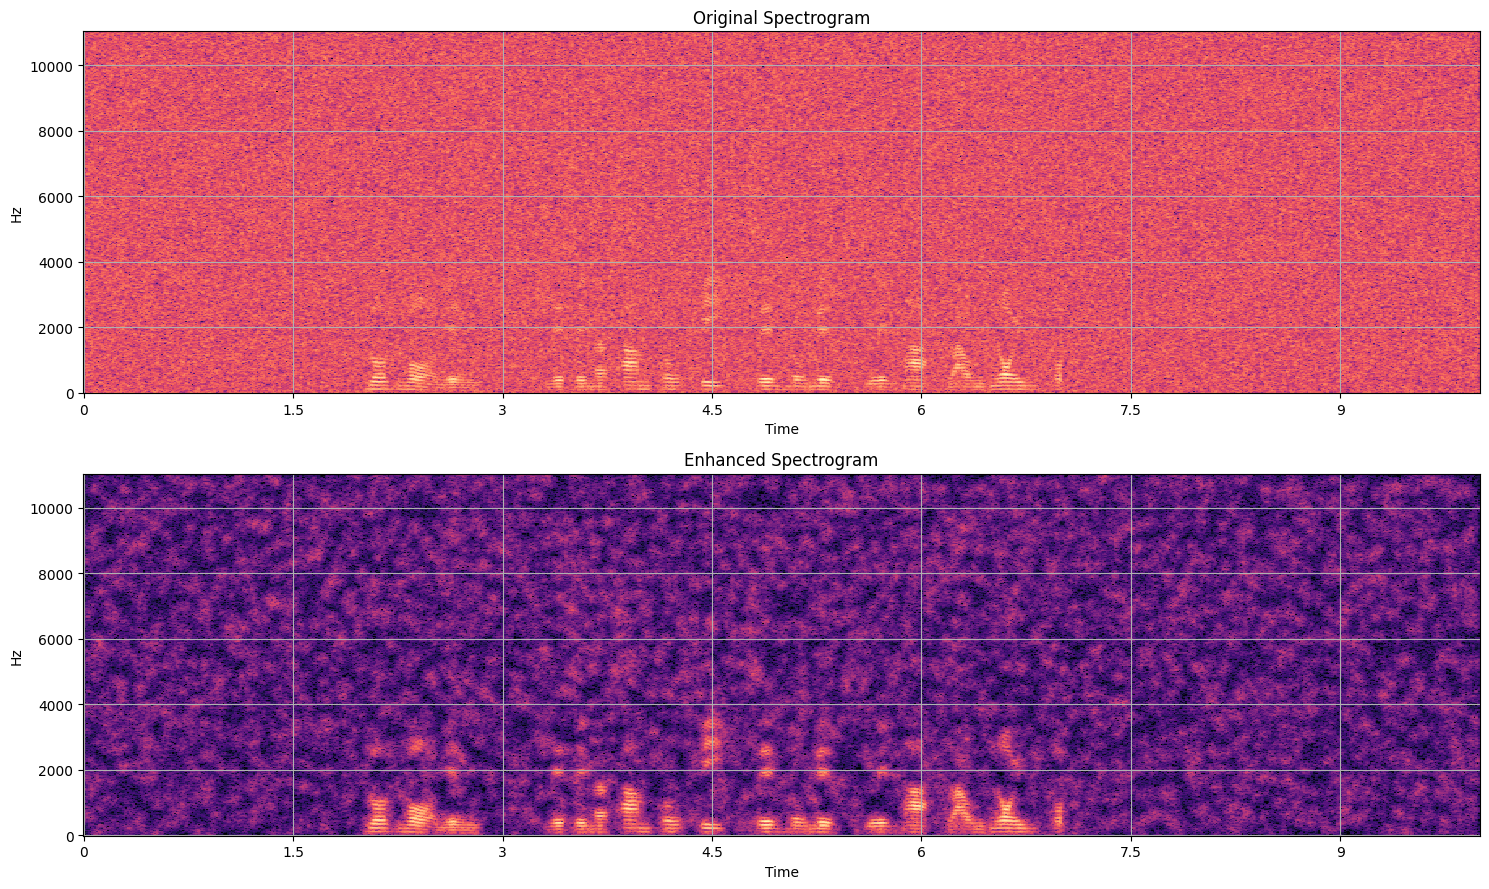

In [21]:
# Compare original and enhanced spectrograms

original_spec = librosa.amplitude_to_db(
    np.abs(
        librosa.stft(
            audio_mono,
            n_fft=1024,
            hop_length=256
        )
    ),
    ref=np.max
)

enhanced_spec = librosa.amplitude_to_db(
    np.abs(
        librosa.stft(
            reduced_audio,
            n_fft=1024,
            hop_length=256
        )
    ),
    ref=np.max
)

fig, axes = plt.subplots(2, 1, figsize=(15, 9))

librosa.display.specshow(
    original_spec,
    sr=sr,
    hop_length=256,
    x_axis="time",
    y_axis="hz",
    ax=axes[0]
)

axes[0].set_title("Original Spectrogram")

librosa.display.specshow(
    enhanced_spec,
    sr=sr,
    hop_length=256,
    x_axis="time",
    y_axis="hz",
    ax=axes[1]
)

axes[1].set_title("Enhanced Spectrogram")

plt.tight_layout()
plt.show()    

In [22]:
# Extract MFCC 

mfcc = librosa.feature.mfcc(
    y=reduced_audio,
    sr=sr,
    n_mfcc=13,
    n_fft=1024,
    hop_length=256,
    n_mels=40
)

print("MFCC Shape:", mfcc.shape)

MFCC Shape: (13, 862)


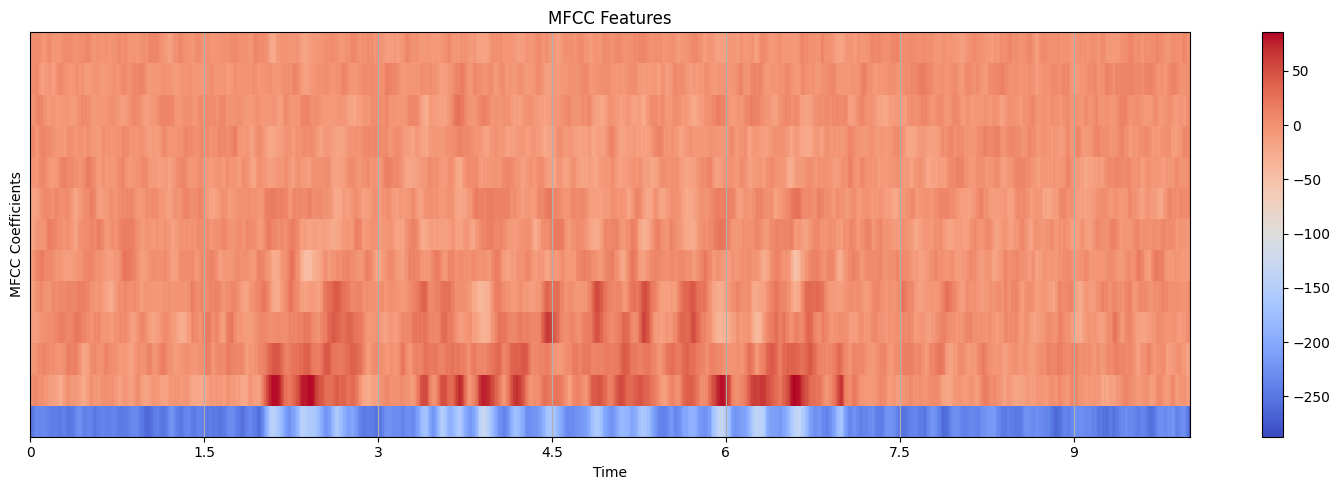

In [23]:
plt.figure(figsize=(15, 5))

librosa.display.specshow(
    mfcc,
    sr=sr,
    hop_length=256,
    x_axis="time"
)

plt.colorbar()

plt.title("MFCC Features")
plt.xlabel("Time")
plt.ylabel("MFCC Coefficients")

plt.tight_layout()
plt.show()

In [24]:
features = {

    "RMS": librosa.feature.rms(
        y=reduced_audio,
        frame_length=1024,
        hop_length=256
    )[0],

    "ZCR": librosa.feature.zero_crossing_rate(
        reduced_audio,
        frame_length=1024,
        hop_length=256
    )[0],

    "Spectral Centroid": librosa.feature.spectral_centroid(
        y=reduced_audio,
        sr=sr,
        n_fft=1024,
        hop_length=256
    )[0]
}

for name, values in features.items():

    print(
        name,
        "Shape:",
        values.shape,
        "Mean:",
        np.mean(values)
    )

RMS Shape: (862,) Mean: 0.015568192
ZCR Shape: (862,) Mean: 0.38057161760440833
Spectral Centroid Shape: (862,) Mean: 4566.194223985633


In [25]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Selected Device:", device)

if device == "cuda":

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Selected Device: cuda
GPU: NVIDIA GeForce GTX 1650


In [26]:
model = whisper.load_model(
    "base",
    device=device
)

In [27]:
original_result = model.transcribe(
    audio_path,
    task="transcribe",
    fp16=(device == "cuda")
)

original_text = original_result["text"]

print("Original Audio Transcription:")
print(original_text)

Original Audio Transcription:
 lquality nói đàng


In [28]:
enhanced_result = model.transcribe(
    enhanced_path,
    task="transcribe",
    fp16=(device == "cuda")
)

enhanced_text = enhanced_result["text"]

print("Enhanced Audio Transcription:")
print(enhanced_text)

Enhanced Audio Transcription:
 Rất lòi d Executive Resources Fund quay v Definitely is a full-個人


In [29]:
from jiwer import wer, cer

reference = """
Welcome to samplolid.com, a free online resource for downloading sample files in a wide variety of digital formats, whether you are 
a software developer testing file upload functionality, a quality assurance engineer validating media players, a student learning 
about digital formats, or simply someone who needs a quick test file. Samplolid provides ready to use files that you can download 
instantly, completely free of charge. In this recording, we will walk you through every aspect of the samplolid platform, exploring
the formats we offer, the technical details behind each one, and the many ways these test files can be used in your projects and 
workflows, let us begin with image formats. Images are perhaps the most fundamental type of digital media, and samplolid offers 
test files in five major image formats, JPEG, PNG, SVG, GIF, and web. Image format has its own strengths, trade-offs, and ideal use
cases, and understanding these differences as essential.
"""

original_wer = wer(
    reference,
    original_text
)

enhanced_wer = wer(
    reference,
    enhanced_text
)

original_cer = cer(
    reference,
    original_text
)

enhanced_cer = cer(
    reference,
    enhanced_text
)

print("Original WER:", original_wer * 100, "%")
print("Enhanced WER:", enhanced_wer * 100, "%")

print("Original CER:", original_cer * 100, "%")
print("Enhanced CER:", enhanced_cer * 100, "%")

Original WER: 100.0 %
Enhanced WER: 99.3421052631579 %
Original CER: 98.56262833675564 %
Enhanced CER: 94.55852156057495 %


In [30]:
report = {
    "Audio File": audio_path,

    "Duration (seconds)": round(duration, 2),

    "Sampling Rate (Hz)": sr,

    "Channels": channels,

    "Bit Depth": bit_depth,

    "Original RMS": round(
        calculate_rms(audio_mono), 6
    ),

    "Noise Sample RMS": round(
        noise_rms, 6
    ),

    "Estimated SNR (dB)": round(
        estimated_snr, 2
    ),

    "Enhanced RMS": round(
        calculate_rms(reduced_audio), 6
    ),

    "MFCC Coefficients": mfcc.shape[0],

    "Original Transcription": original_text,

    "Enhanced Transcription": enhanced_text
}

for key, value in report.items():

    print(f"{key}: {value}")

Audio File: 10_second_speech_with_noise.wav
Duration (seconds): 10.0
Sampling Rate (Hz): 22050
Channels: 1
Bit Depth: 16
Original RMS: 0.11250100284814835
Noise Sample RMS: 0.10039699822664261
Estimated SNR (dB): 0.9900000095367432
Enhanced RMS: 0.026986999437212944
MFCC Coefficients: 13
Original Transcription:  lquality nói đàng
Enhanced Transcription:  Rất lòi d Executive Resources Fund quay v Definitely is a full-個人


In [31]:
report_df = pd.DataFrame(
    report.items(),
    columns=["Property", "Value"]
)

report_df.to_csv(
    "output/audio_analysis_report.csv",
    index=False
)

print("Analysis report saved!")

Analysis report saved!
